In [1]:
#Drive mount
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
#패키지 설치
!pip install -q segmentation-models-pytorch timm albumentations lightgbm scikit-image opencv-python-headless joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.7 MB/s eta 0:00:00


In [3]:
#코드 있는지 확인
!ls -lh /content/drive/MyDrive/forensic_project_v2/checkpoints
!ls -lh /content/drive/MyDrive/forensic_project_v2/results

total 81M
-rw------- 1 root root 81M Jun  7 11:40 run0_best.pth
total 1.1M
-rw------- 1 root root  579 Jun  7 15:20 best_config.json
-rw------- 1 root root 4.9K Jun  7 15:20 cv_results.csv
-rw------- 1 root root 347K Jun  7 15:22 predictions_test.csv
-rw------- 1 root root  262 Jun  7 15:22 shap_importance.csv
-rw------- 1 root root  500 Jun  7 12:07 stage1_training_log.json
-rw------- 1 root root  58K Jun  7 15:20 stage2_lgbm.pkl
-rw------- 1 root root  334 Jun  7 15:22 test_metrics.json
-rw------- 1 root root 699K Jun  7 15:20 validation_predictions.csv
drwx------ 2 root root 4.0K Jun  7 15:22 visualizations


실시간 판별만 하려면:

forensic_project_v2/
├─ utils.py
├─ checkpoints/
│  └─ run0_best.pth
└─ results/
   ├─ stage2_lgbm.pkl
   └─ best_config.json

그리고 사진 1장.

In [4]:
import os
import sys
import json
from pathlib import Path

import cv2
import joblib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp

BASE_DIR = "/content/drive/MyDrive/forensic_project_v2"
sys.path.insert(0, BASE_DIR)

from utils import letterbox_resize, extract_features

CKPT_PATH = f"{BASE_DIR}/checkpoints/run0_best.pth"
MODEL_PATH = f"{BASE_DIR}/results/stage2_lgbm.pkl"
CONFIG_PATH = f"{BASE_DIR}/results/best_config.json"

assert os.path.exists(CKPT_PATH), f"Stage1 checkpoint 없음: {CKPT_PATH}"
assert os.path.exists(MODEL_PATH), f"Stage2 model 없음: {MODEL_PATH}"
assert os.path.exists(CONFIG_PATH), f"best_config 없음: {CONFIG_PATH}"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    cfg = json.load(f)

print("best_config:", cfg)

TARGET_SIZE = 512
MIN_AREA = 400

HEATMAP_THR = float(cfg["threshold"])
TOP_K = int(cfg["top_k"])
CLASSIFY_THR = float(cfg["classify_threshold"])
FEAT_COLS = cfg["feat_cols"]

def build_stage1_model():
    return smp.UnetPlusPlus(
        encoder_name="efficientnet-b4",
        encoder_weights=None,
        in_channels=3,
        classes=1,
        activation=None,
    )

stage1 = build_stage1_model().to(device)
stage1.load_state_dict(torch.load(CKPT_PATH, map_location=device))
stage1.eval()

stage2 = joblib.load(MODEL_PATH)

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def preprocess_image(image_path):
    img_bgr = cv2.imread(str(image_path))
    if img_bgr is None:
        raise FileNotFoundError(f"이미지를 읽지 못했습니다: {image_path}")

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_512 = letterbox_resize(img_rgb, TARGET_SIZE)

    x = img_512.astype(np.float32) / 255.0
    x = (x - IMAGENET_MEAN) / IMAGENET_STD
    x = torch.from_numpy(x).permute(2, 0, 1).unsqueeze(0).float()

    return img_rgb, img_512, x

@torch.no_grad()
def predict_one_image(image_path, save_path=None):
    original_rgb, image_512, x = preprocess_image(image_path)

    x = x.to(device)

    pred = torch.sigmoid(stage1(x))[0, 0].detach().cpu().numpy()
    heatmap = pred.astype(np.float32)

    # -----------------------------
    # 1. Stage 2 feature extraction
    # -----------------------------
    feats = extract_features(
        image_rgb=image_512,
        heatmap=heatmap,
        threshold=HEATMAP_THR,
        top_k=TOP_K,
        min_area=MIN_AREA,
    )

    feat_df = pd.DataFrame([{c: feats.get(c, 0.0) for c in FEAT_COLS}])

    # warning 제거: .values 말고 DataFrame 그대로 넣기
    prob_composite = float(stage2.predict_proba(feat_df)[0, 1])
    pred_label = int(prob_composite >= CLASSIFY_THR)
    label_name = "composite" if pred_label == 1 else "real"

    # -----------------------------
    # 2. Heatmap statistics
    # -----------------------------
    heatmap_raw = heatmap.copy()

    h_min = float(heatmap_raw.min())
    h_max = float(heatmap_raw.max())
    h_mean = float(heatmap_raw.mean())
    h_std = float(heatmap_raw.std())

    print("=" * 70)
    print("입력 이미지:", image_path)
    print("예측 결과:", label_name)
    print(f"composite 확률: {prob_composite:.4f}")
    print(f"classification threshold: {CLASSIFY_THR}")
    print(f"heatmap threshold: {HEATMAP_THR}")
    print(f"top-k: {TOP_K}")
    print("-" * 70)
    print(f"heatmap min : {h_min:.4f}")
    print(f"heatmap max : {h_max:.4f}")
    print(f"heatmap mean: {h_mean:.4f}")
    print(f"heatmap std : {h_std:.4f}")
    print("=" * 70)

    # normalized heatmap: 보기 좋게 상대적 강조
    if h_max > h_min:
        heatmap_vis = (heatmap_raw - h_min) / (h_max - h_min)
    else:
        heatmap_vis = np.zeros_like(heatmap_raw)

    # -----------------------------
    # 3. Threshold mask + bbox
    # -----------------------------
    binary = (heatmap_raw > HEATMAP_THR).astype(np.uint8)

    num_l, label_map, stats, _ = cv2.connectedComponentsWithStats(binary)

    valid = []
    for lid in range(1, num_l):
        area = int(stats[lid, cv2.CC_STAT_AREA])

        if area >= MIN_AREA:
            region_mask = label_map == lid
            score = float(heatmap_raw[region_mask].mean())
            x0, y0, w, h, _ = stats[lid]

            valid.append({
                "area": area,
                "score": score,
                "bbox": [int(x0), int(y0), int(w), int(h)]
            })

    valid.sort(key=lambda r: r["score"], reverse=True)
    valid = valid[:TOP_K]

    draw = image_512.copy()
    for r in valid:
        x0, y0, w, h = r["bbox"]
        cv2.rectangle(draw, (x0, y0), (x0 + w, y0 + h), (255, 50, 50), 3)

    print("\n===== Suspicious Regions =====")
    if len(valid) == 0:
        print("threshold를 넘는 의심 영역 없음")
    else:
        for i, r in enumerate(valid, 1):
            print(
                f"{i}. bbox={r['bbox']}, "
                f"area={r['area']}, "
                f"score={r['score']:.4f}"
            )

    print("\n===== Extracted Features =====")
    for k, v in feats.items():
        if isinstance(v, (int, float, np.integer, np.floating)):
            print(f"{k:30s}: {float(v):.6f}")

    # -----------------------------
    # 4. Visualization
    # -----------------------------
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))

    axes[0].imshow(image_512)
    axes[0].set_title("Input image\nletterbox 512")
    axes[0].axis("off")

    axes[1].imshow(image_512)
    axes[1].imshow(
        heatmap_raw,
        cmap="jet",
        alpha=0.55,
        vmin=0,
        vmax=1
    )
    axes[1].set_title(
        f"Raw heatmap\n"
        f"max={h_max:.3f}, mean={h_mean:.3f}"
    )
    axes[1].axis("off")

    axes[2].imshow(image_512)
    axes[2].imshow(
        heatmap_vis,
        cmap="jet",
        alpha=0.55,
        vmin=0,
        vmax=1
    )
    axes[2].set_title("Normalized heatmap\nvisualization only")
    axes[2].axis("off")

    axes[3].imshow(draw)
    axes[3].imshow(binary, cmap="Reds", alpha=0.35)
    axes[3].set_title(
        f"Threshold mask + bbox\n"
        f"thr={HEATMAP_THR}, boxes={len(valid)}\n"
        f"Prediction: {label_name}, P={prob_composite:.3f}"
    )
    axes[3].axis("off")

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print("\n저장:", save_path)

    plt.show()

    return {
        "image_path": str(image_path),
        "pred_label": pred_label,
        "pred_name": label_name,
        "prob_composite": prob_composite,
        "heatmap_min": h_min,
        "heatmap_max": h_max,
        "heatmap_mean": h_mean,
        "heatmap_std": h_std,
        "heatmap": heatmap_raw,
        "heatmap_vis": heatmap_vis,
        "features": feats,
        "boxes": valid,
    }

device: cuda
best_config: {'threshold': 0.4, 'top_k': 3, 'feat_version': 'Version1', 'feat_cols': ['max_suspicious_score', 'mean_suspicious_score', 'suspicious_area_ratio', 'top_k_score_mean', 'brightness_diff', 'roi_brightness_std'], 'lgbm_params': {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 4, 'min_child_samples': 50, 'num_leaves': 15, 'verbose': -1, 'random_state': 42, 'n_jobs': -1}, 'classify_threshold': 0.35, 'validation_f1_at_classify_threshold': 0.8537588419147886, 'cv_mean_f1': 0.8870853564813581}


Saving 10001_000000207620.png to 10001_000000207620.png


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


입력 이미지: /content/10001_000000207620.png
예측 결과: real
composite 확률: 0.0855
classification threshold: 0.35
heatmap threshold: 0.4
top-k: 3
저장: /content/demo_prediction.png


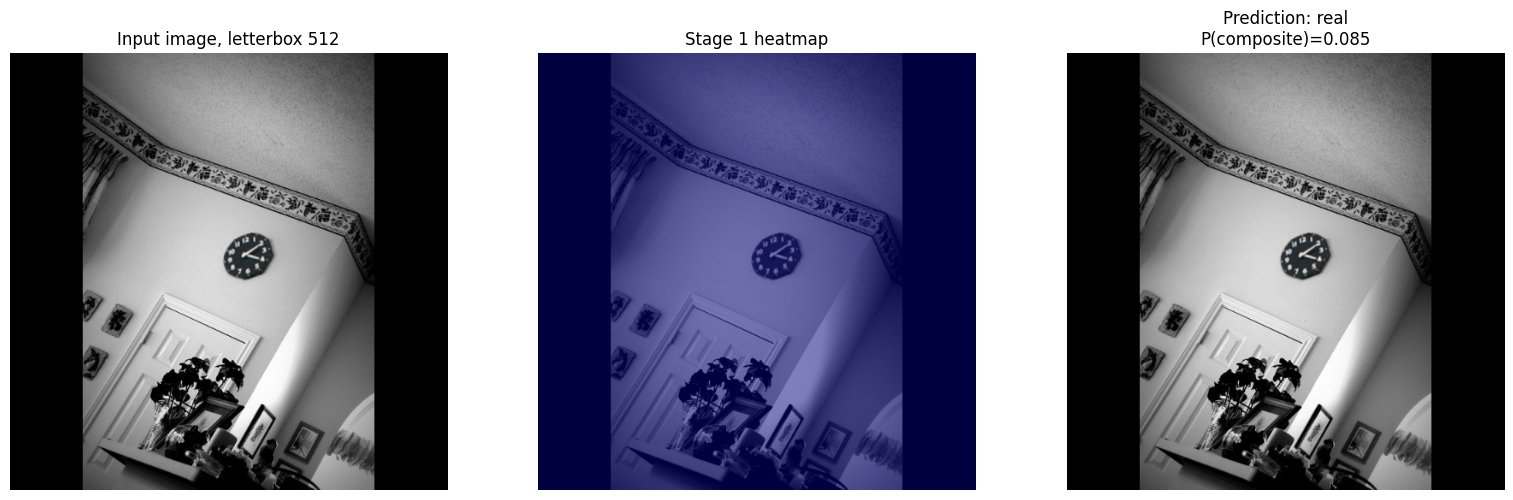

In [6]:
from google.colab import files

uploaded = files.upload()
image_path = "/content/" + list(uploaded.keys())[0]

result = predict_one_image(
    image_path,
    save_path="/content/demo_prediction.png"
)

Saving 10005_000000002931.png to 10005_000000002931.png
입력 이미지: /content/10005_000000002931.png
예측 결과: composite
composite 확률: 0.5965
classification threshold: 0.35
heatmap threshold: 0.4
top-k: 3


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


저장: /content/demo_prediction.png


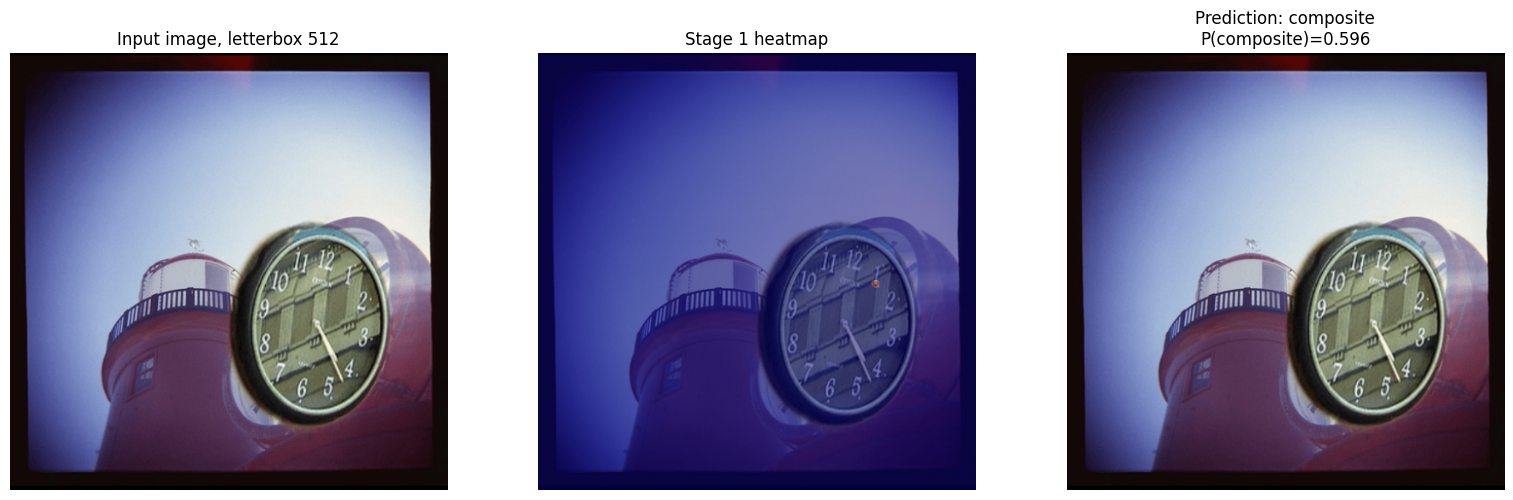

In [7]:
from google.colab import files

uploaded = files.upload()
image_path = "/content/" + list(uploaded.keys())[0]

result = predict_one_image(
    image_path,
    save_path="/content/demo_prediction.png"
)

Saving demo_prediction.png to demo_prediction (1).png
입력 이미지: /content/demo_prediction (1).png
예측 결과: real
composite 확률: 0.0855
classification threshold: 0.35
heatmap threshold: 0.4
top-k: 3


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


저장: /content/demo_prediction.png


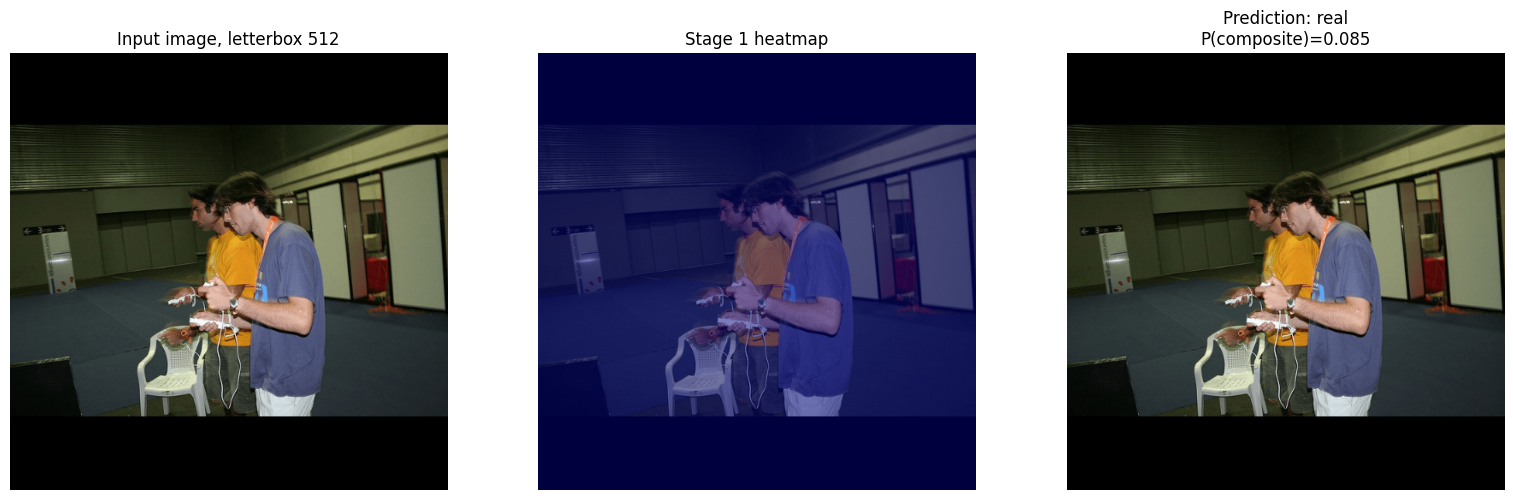

In [8]:
from google.colab import files

uploaded = files.upload()
image_path = "/content/" + list(uploaded.keys())[0]

result = predict_one_image(
    image_path,
    save_path="/content/demo_prediction.png"
)

Saving 10008_000000076885.png to 10008_000000076885.png
입력 이미지: /content/10008_000000076885.png
예측 결과: real
composite 확률: 0.0843
classification threshold: 0.35
heatmap threshold: 0.4
top-k: 3


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


저장: /content/demo_prediction.png


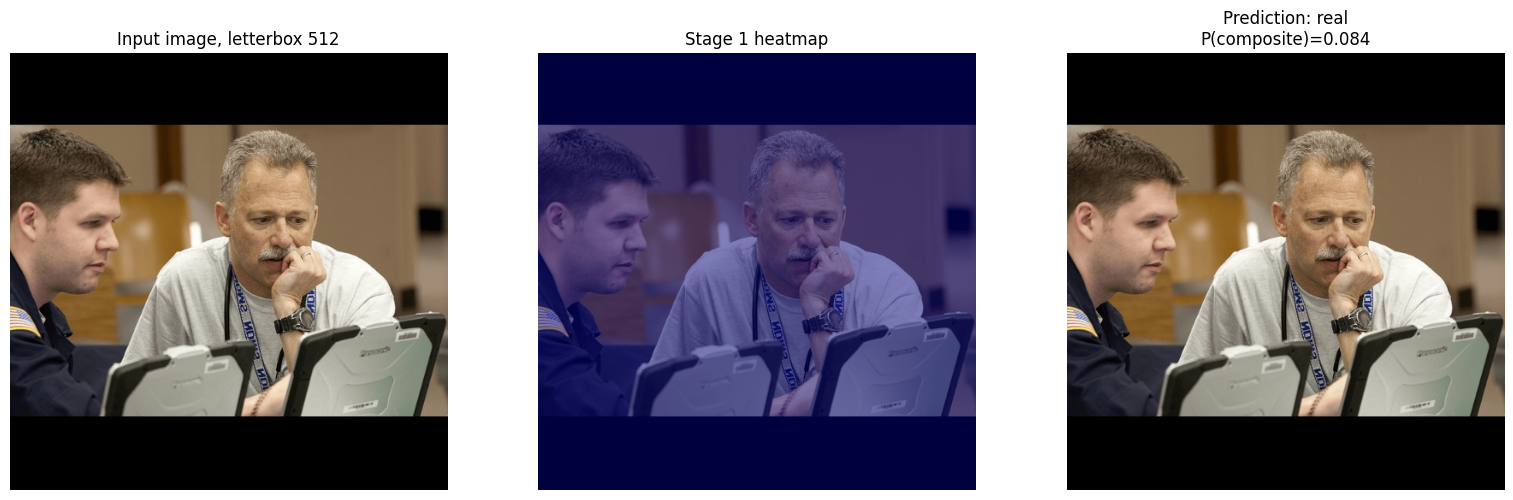

In [9]:
  from google.colab import files

uploaded = files.upload()
image_path = "/content/" + list(uploaded.keys())[0]

result = predict_one_image(
    image_path,
    save_path="/content/demo_prediction.png"
)

Saving 10012_000000502996.tif to 10012_000000502996.tif
입력 이미지: /content/10012_000000502996.tif
예측 결과: real
composite 확률: 0.0882
classification threshold: 0.35
heatmap threshold: 0.4
top-k: 3


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


저장: /content/demo_prediction.png


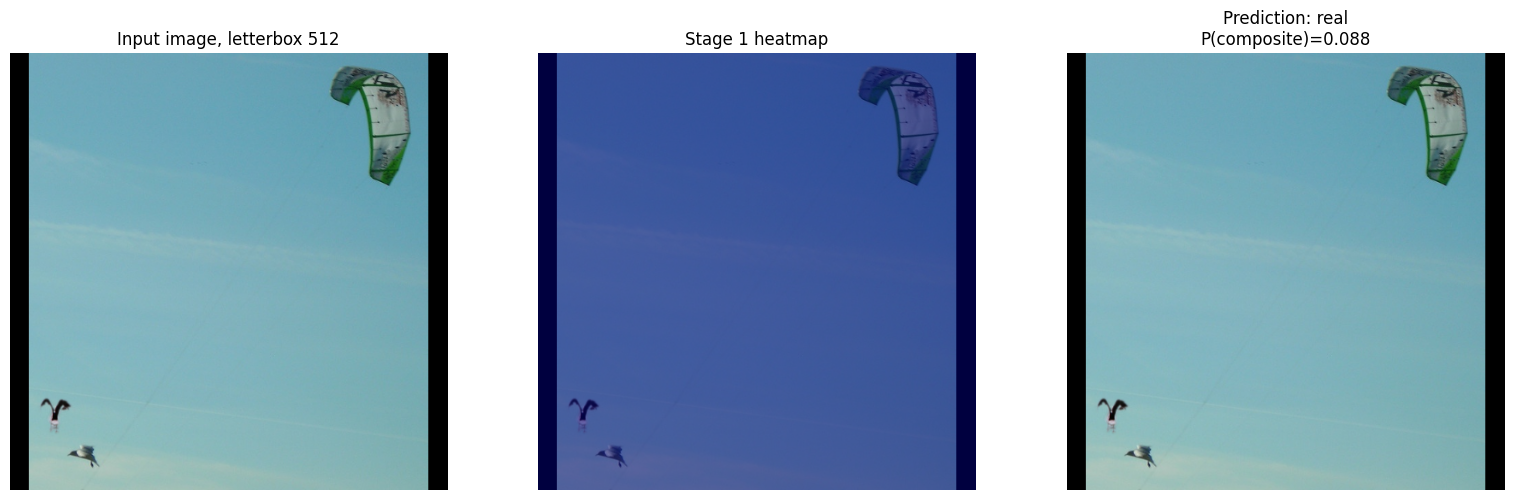

In [10]:
from google.colab import files

uploaded = files.upload()
image_path = "/content/" + list(uploaded.keys())[0]

result = predict_one_image(
    image_path,
    save_path="/content/demo_prediction.png"
)

Saving 10012_000000502996.tif to 10012_000000502996.tif
입력 이미지: /content/10012_000000502996.tif
예측 결과: real
composite 확률: 0.0882
classification threshold: 0.35
heatmap threshold: 0.4
top-k: 3
----------------------------------------------------------------------
heatmap min : 0.0000
heatmap max : 0.0001
heatmap mean: 0.0000
heatmap std : 0.0000

===== Suspicious Regions =====
threshold를 넘는 의심 영역 없음

===== Extracted Features =====
max_suspicious_score          : 0.000080
mean_suspicious_score         : 0.000000
suspicious_area_ratio         : 0.000000
top_k_score_mean              : 0.000000
brightness_diff               : 0.000000
roi_brightness_std            : 0.000000
rgb_mean_diff                 : 0.000000
color_distance                : 0.000000
hsv_saturation_diff           : 0.000000
hsv_value_diff                : 0.000000
boundary_edge_strength        : 0.000000
boundary_gradient_mean        : 0.000000
laplacian_variance            : 0.000000
lbp_hist_diff                 : 0

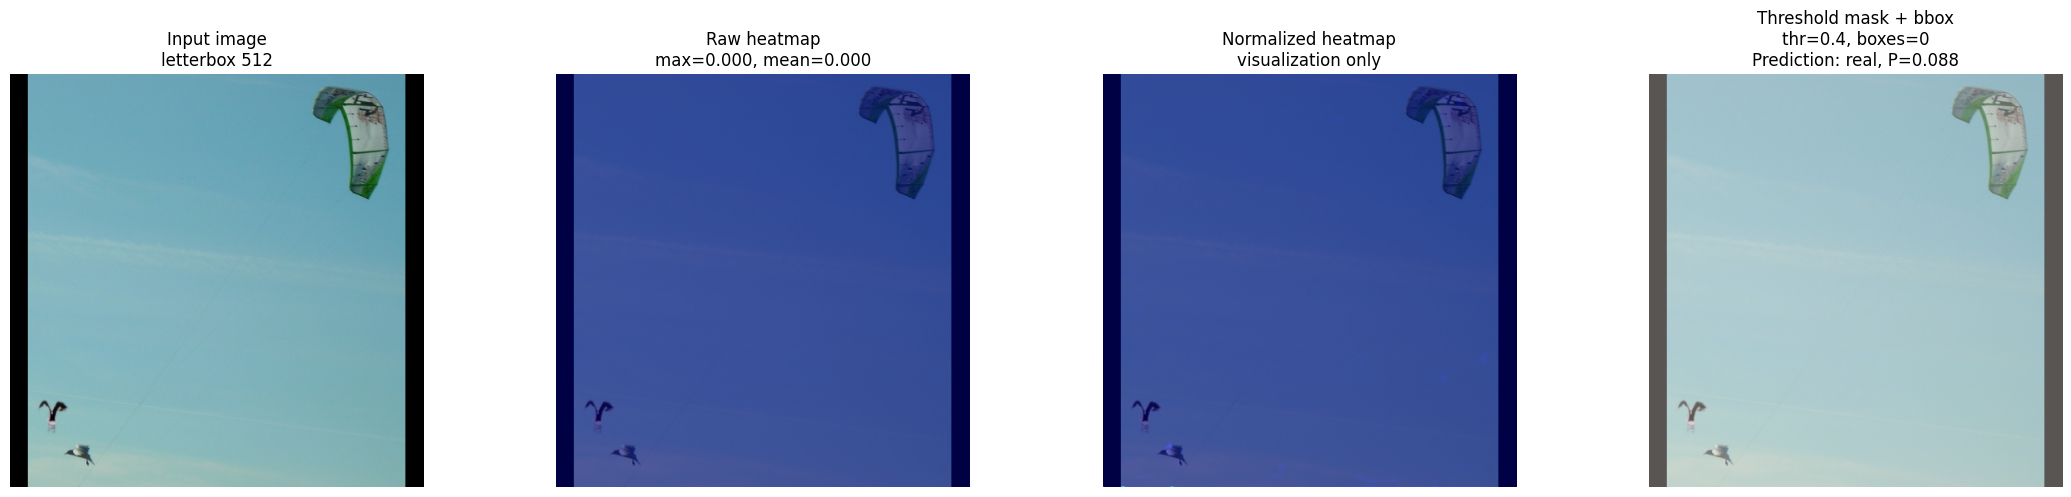

In [5]:
from google.colab import files

uploaded = files.upload()
image_path = "/content/" + list(uploaded.keys())[0]

result = predict_one_image(
    image_path,
    save_path="/content/demo_prediction.png"
)

Saving 10005_000000002931.tif to 10005_000000002931.tif
입력 이미지: /content/10005_000000002931.tif
예측 결과: composite
composite 확률: 0.5965
classification threshold: 0.35
heatmap threshold: 0.4
top-k: 3
----------------------------------------------------------------------
heatmap min : 0.0000
heatmap max : 0.9975
heatmap mean: 0.0002
heatmap std : 0.0144

===== Suspicious Regions =====
threshold를 넘는 의심 영역 없음

===== Extracted Features =====
max_suspicious_score          : 0.997475
mean_suspicious_score         : 0.000230
suspicious_area_ratio         : 0.000233
top_k_score_mean              : 0.000000
brightness_diff               : 0.000000
roi_brightness_std            : 0.000000
rgb_mean_diff                 : 0.000000
color_distance                : 0.000000
hsv_saturation_diff           : 0.000000
hsv_value_diff                : 0.000000
boundary_edge_strength        : 0.000000
boundary_gradient_mean        : 0.000000
laplacian_variance            : 0.000000
lbp_hist_diff               

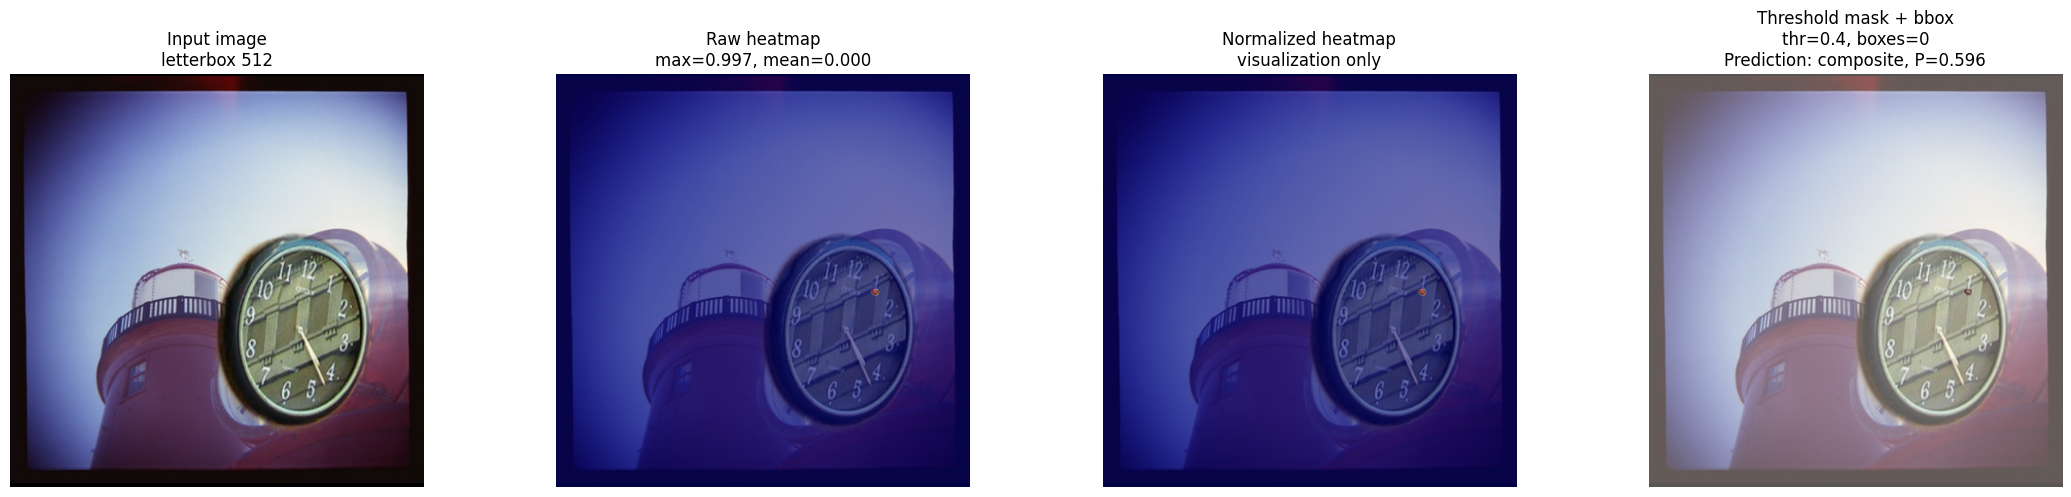

In [6]:
from google.colab import files

uploaded = files.upload()
image_path = "/content/" + list(uploaded.keys())[0]

result = predict_one_image(
    image_path,
    save_path="/content/demo_prediction.png"
)

Saving 74_000000409510.tif to 74_000000409510.tif
입력 이미지: /content/74_000000409510.tif
예측 결과: composite
composite 확률: 0.9658
classification threshold: 0.35
heatmap threshold: 0.4
top-k: 3
----------------------------------------------------------------------
heatmap min : 0.0000
heatmap max : 1.0000
heatmap mean: 0.0023
heatmap std : 0.0470

===== Suspicious Regions =====
1. bbox=[212, 145, 29, 28], area=623, score=0.9550

===== Extracted Features =====
max_suspicious_score          : 0.999994
mean_suspicious_score         : 0.002344
suspicious_area_ratio         : 0.002377
top_k_score_mean              : 0.954981
brightness_diff               : 47.371351
roi_brightness_std            : 47.486623
rgb_mean_diff                 : 47.021830
color_distance                : 83.170780
hsv_saturation_diff           : 14.925101
hsv_value_diff                : 59.250423
boundary_edge_strength        : 56.146789
boundary_gradient_mean        : 103.321790
laplacian_variance            : 2490.3269

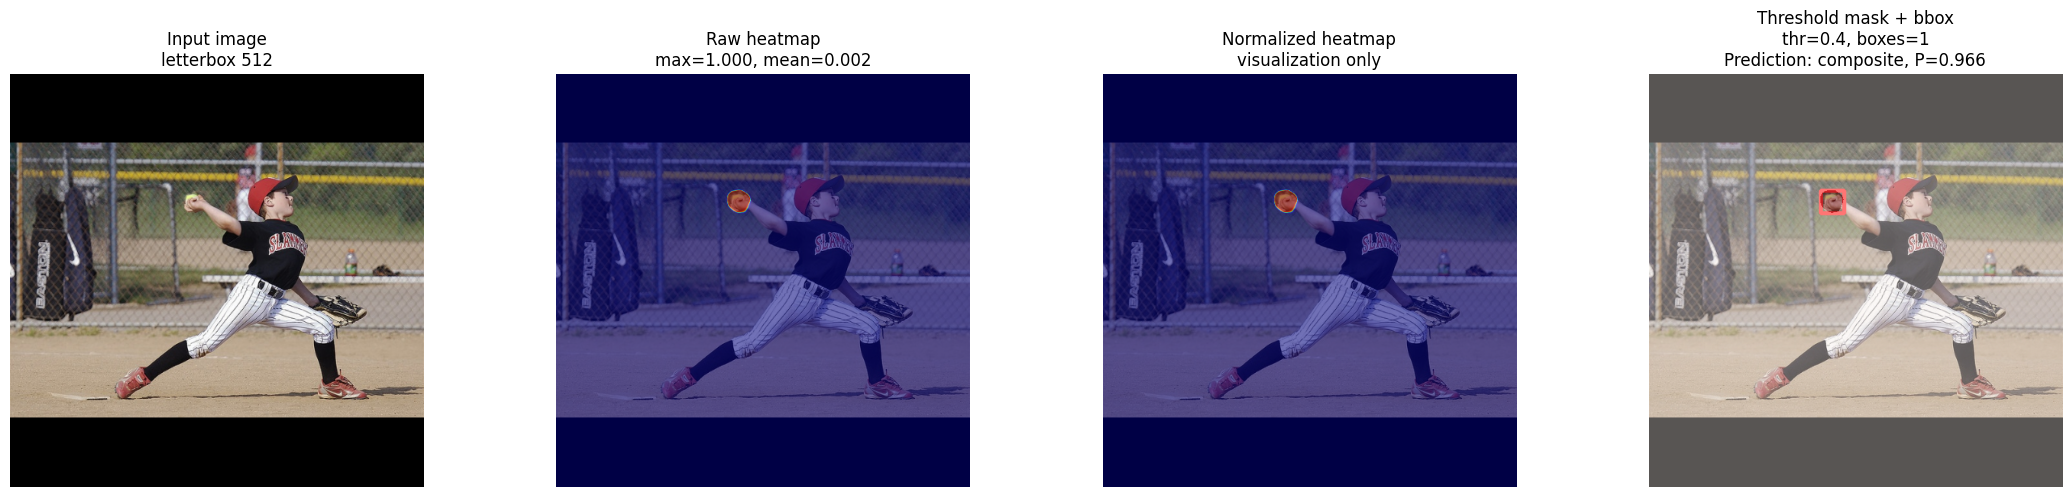

In [7]:
from google.colab import files

uploaded = files.upload()
image_path = "/content/" + list(uploaded.keys())[0]

result = predict_one_image(
    image_path,
    save_path="/content/demo_prediction.png"
)

Saving 24615_000000529964.tif to 24615_000000529964.tif
입력 이미지: /content/24615_000000529964.tif
예측 결과: composite
composite 확률: 0.9658
classification threshold: 0.35
heatmap threshold: 0.4
top-k: 3
----------------------------------------------------------------------
heatmap min : 0.0000
heatmap max : 1.0000
heatmap mean: 0.0030
heatmap std : 0.0534

===== Suspicious Regions =====
1. bbox=[11, 267, 24, 22], area=436, score=0.9823

===== Extracted Features =====
max_suspicious_score          : 1.000000
mean_suspicious_score         : 0.002953
suspicious_area_ratio         : 0.002960
top_k_score_mean              : 0.982268
brightness_diff               : 38.416057
roi_brightness_std            : 50.921627
rgb_mean_diff                 : 28.490972
color_distance                : 59.942117
hsv_saturation_diff           : 10.444843
hsv_value_diff                : 31.891330
boundary_edge_strength        : 0.000000
boundary_gradient_mean        : 15.769366
laplacian_variance            : 117

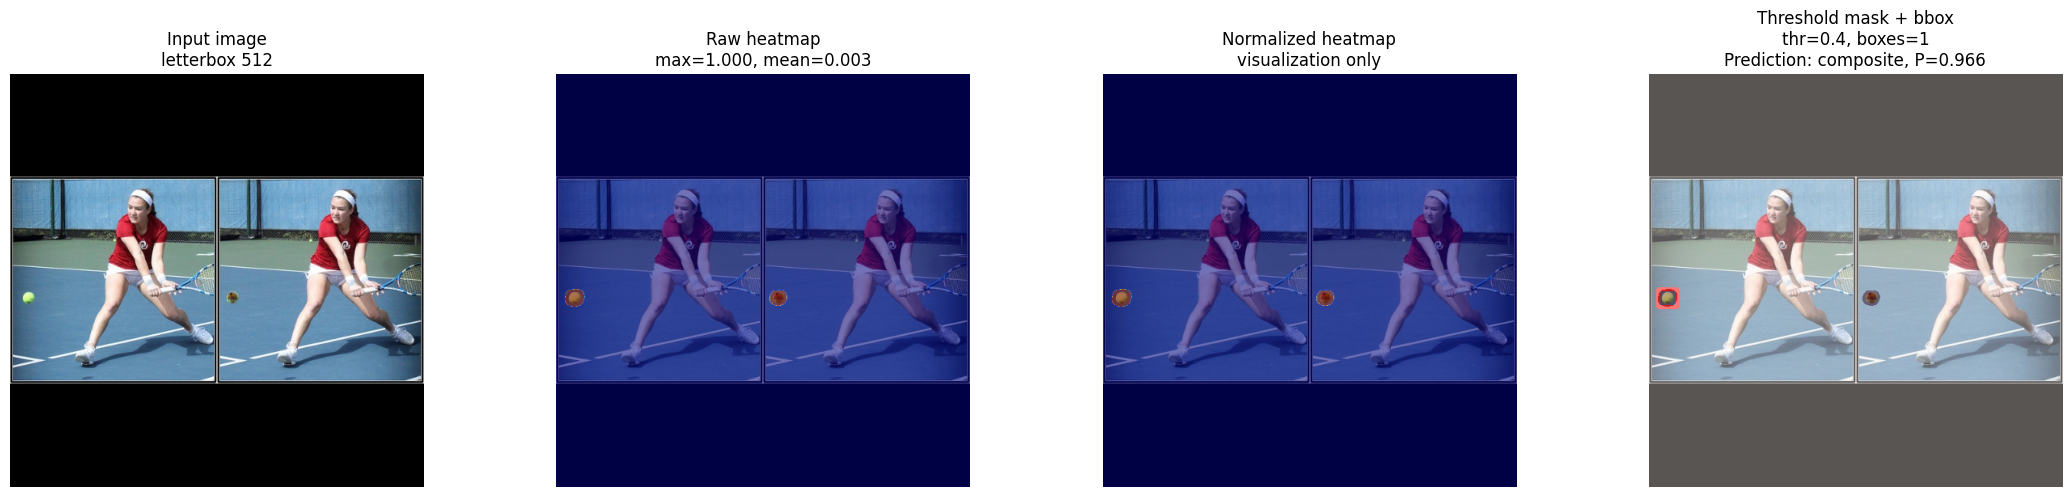

In [8]:
from google.colab import files

uploaded = files.upload()
image_path = "/content/" + list(uploaded.keys())[0]

result = predict_one_image(
    image_path,
    save_path="/content/demo_prediction.png"
)

Saving 24618_000000555131.tif to 24618_000000555131.tif
입력 이미지: /content/24618_000000555131.tif
예측 결과: composite
composite 확률: 0.9521
classification threshold: 0.35
heatmap threshold: 0.4
top-k: 3
----------------------------------------------------------------------
heatmap min : 0.0000
heatmap max : 1.0000
heatmap mean: 0.0007
heatmap std : 0.0263

===== Suspicious Regions =====
threshold를 넘는 의심 영역 없음

===== Extracted Features =====
max_suspicious_score          : 0.999999
mean_suspicious_score         : 0.000728
suspicious_area_ratio         : 0.000732
top_k_score_mean              : 0.000000
brightness_diff               : 0.000000
roi_brightness_std            : 0.000000
rgb_mean_diff                 : 0.000000
color_distance                : 0.000000
hsv_saturation_diff           : 0.000000
hsv_value_diff                : 0.000000
boundary_edge_strength        : 0.000000
boundary_gradient_mean        : 0.000000
laplacian_variance            : 0.000000
lbp_hist_diff               

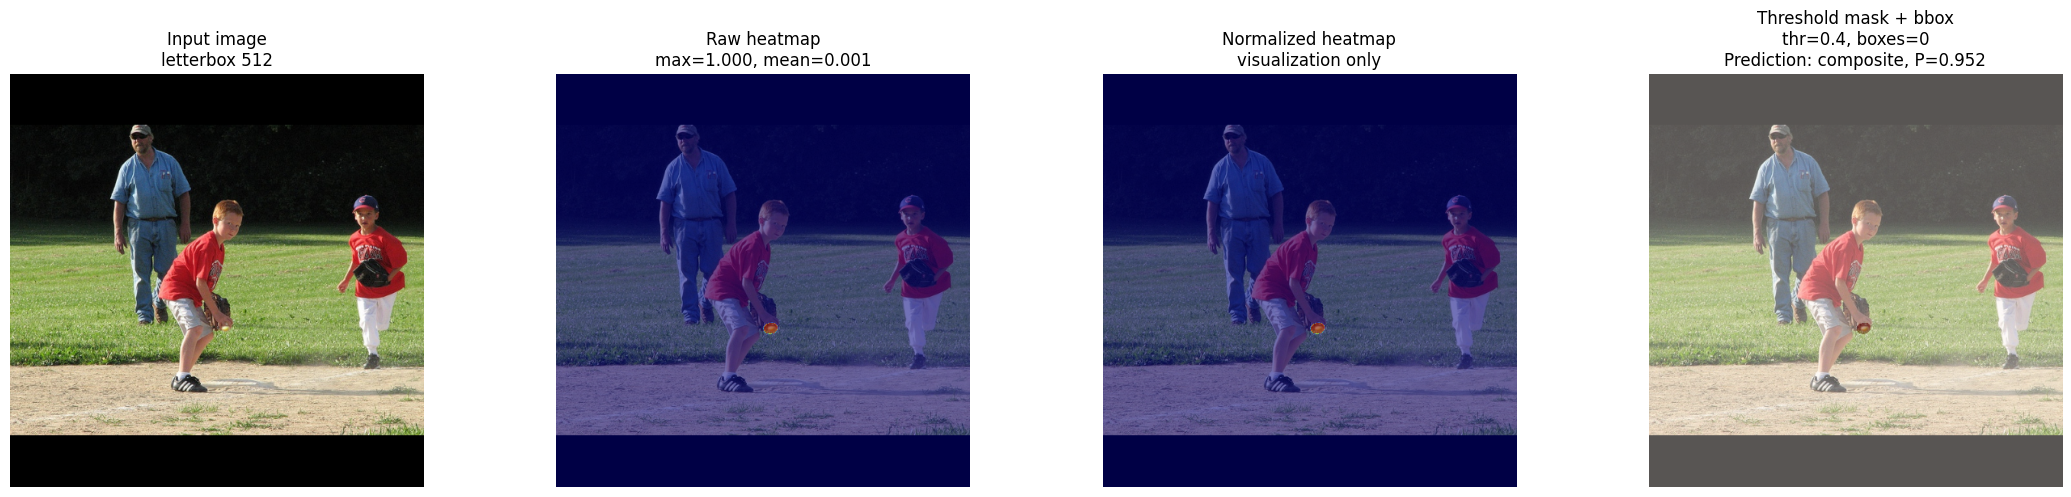

In [9]:
from google.colab import files

uploaded = files.upload()
image_path = "/content/" + list(uploaded.keys())[0]

result = predict_one_image(
    image_path,
    save_path="/content/demo_prediction.png"
)

Saving 24643_000000528305.tif to 24643_000000528305.tif
입력 이미지: /content/24643_000000528305.tif
예측 결과: real
composite 확률: 0.1885
classification threshold: 0.35
heatmap threshold: 0.4
top-k: 3
----------------------------------------------------------------------
heatmap min : 0.0000
heatmap max : 0.9917
heatmap mean: 0.0031
heatmap std : 0.0508

===== Suspicious Regions =====
1. bbox=[296, 144, 38, 34], area=830, score=0.8726

===== Extracted Features =====
max_suspicious_score          : 0.991696
mean_suspicious_score         : 0.003055
suspicious_area_ratio         : 0.003269
top_k_score_mean              : 0.872586
brightness_diff               : 38.025918
roi_brightness_std            : 55.285691
rgb_mean_diff                 : 34.438410
color_distance                : 62.043600
hsv_saturation_diff           : 111.468789
hsv_value_diff                : 7.401517
boundary_edge_strength        : 85.491329
boundary_gradient_mean        : 191.634160
laplacian_variance            : 2344.

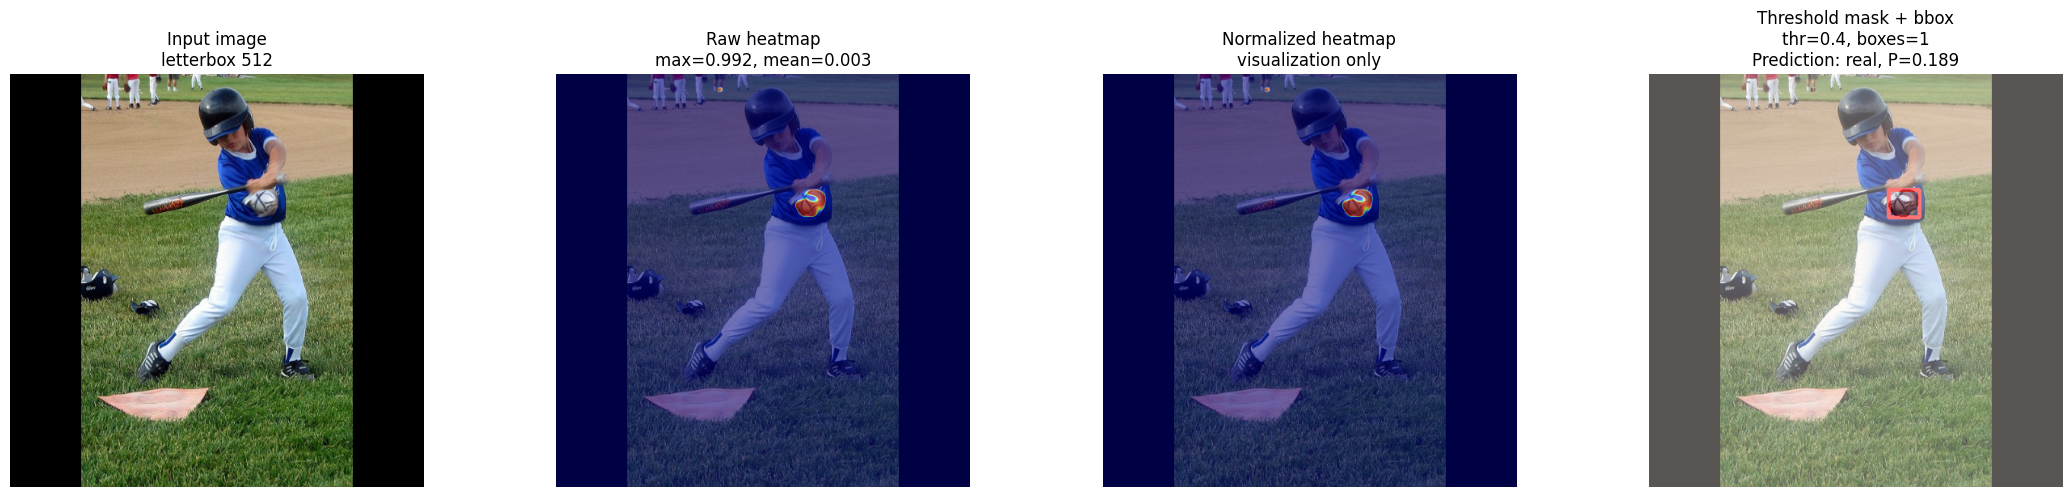

In [10]:
from google.colab import files

uploaded = files.upload()
image_path = "/content/" + list(uploaded.keys())[0]

result = predict_one_image(
    image_path,
    save_path="/content/demo_prediction.png"
)

Saving 24804_000000520752 (1).tif to 24804_000000520752 (1).tif
입력 이미지: /content/24804_000000520752 (1).tif
예측 결과: composite
composite 확률: 0.9574
classification threshold: 0.35
heatmap threshold: 0.4
top-k: 3
----------------------------------------------------------------------
heatmap min : 0.0000
heatmap max : 0.9992
heatmap mean: 0.0017
heatmap std : 0.0401

===== Suspicious Regions =====
1. bbox=[113, 205, 24, 24], area=454, score=0.9554

===== Extracted Features =====
max_suspicious_score          : 0.999204
mean_suspicious_score         : 0.001696
suspicious_area_ratio         : 0.001732
top_k_score_mean              : 0.955411
brightness_diff               : 11.467228
roi_brightness_std            : 23.232216
rgb_mean_diff                 : 8.996408
color_distance                : 19.617291
hsv_saturation_diff           : 35.481079
hsv_value_diff                : 17.892583
boundary_edge_strength        : 85.923913
boundary_gradient_mean        : 110.400763
laplacian_variance   

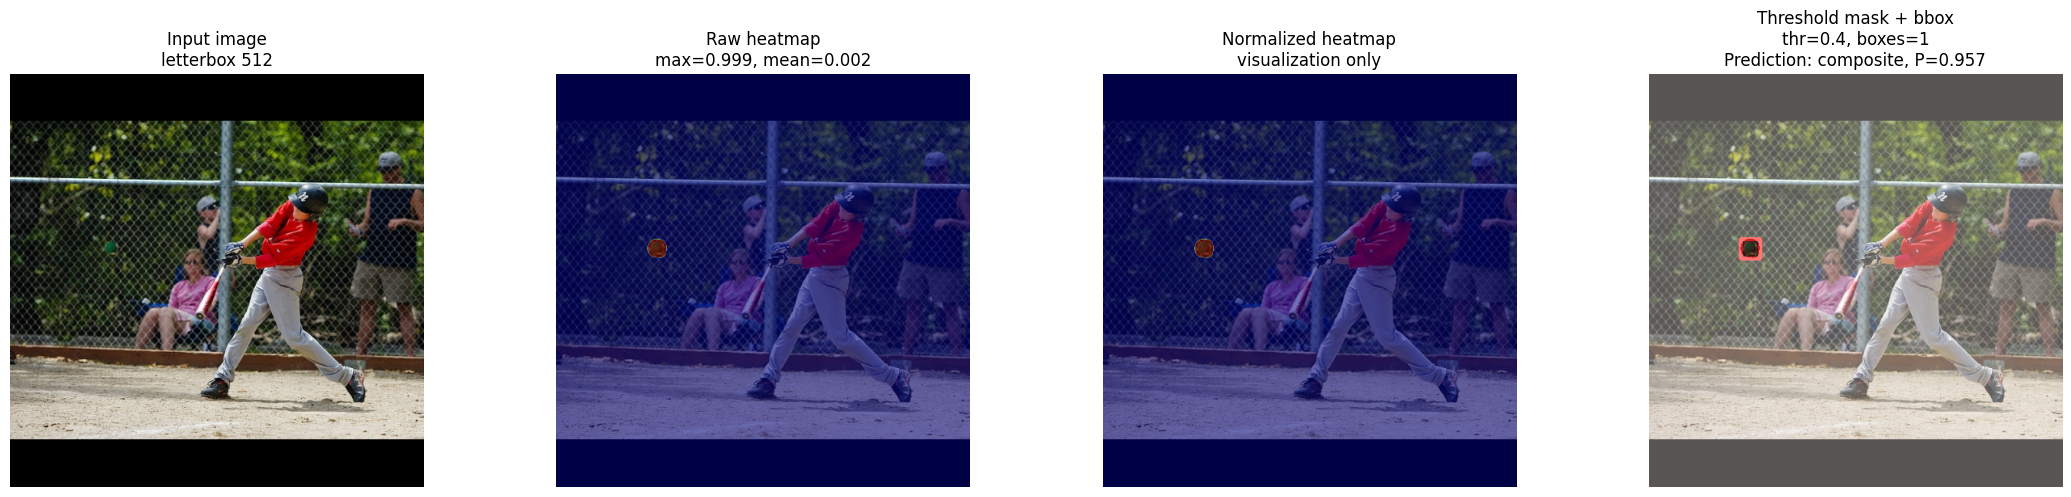

In [11]:
from google.colab import files

uploaded = files.upload()
image_path = "/content/" + list(uploaded.keys())[0]

result = predict_one_image(
    image_path,
    save_path="/content/demo_prediction.png"
)